运行约定：以本 Notebook 所在目录作为工作目录，从第一单元顺序运行。首个代码单元仅建立数据与输出目录。历史输出保留，不代表当前环境已验证。


In [ ]:
from pathlib import Path
Path('../../data').mkdir(parents=True, exist_ok=True)
Path('../../outputs').mkdir(parents=True, exist_ok=True)


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import time
from matplotlib import pyplot as plt

# 一、使用LeNet-5网络结构创建MNIST手写数字识别分类器

MNIST（Modified National Institute of Standards and Technology database）是一个经典的手写数字图像数据集，由美国国家标准与技术研究院（NIST）发布。该数据集包含60,000张训练图像和10,000张测试图像，每张图像都是28×28像素的灰度图，表示0到9的手写数字。MNIST因其规模适中、数据质量高，常被用作机器学习入门和算法基准测试的标准数据集，在深度学习发展初期发挥了重要作用。
MNIST数据集来源于NIST的原始手写数字数据库，经过Yann LeCun等人修改后发布。训练集包含来自250位不同书写者的样本，测试集则来自另外250位书写者，确保了训练和测试数据的独立性。每张图像都经过尺寸归一化和居中处理，像素值范围在0到255之间，通常会被归一化到0到1之间用于模型训练。

MNIST在深度学习发展史上具有里程碑意义。1998年，Yann LeCun等人提出的LeNet-5卷积神经网络在MNIST上取得了突破性成果，错误率降至0.8%以下，首次证明了深度学习在手写字符识别领域的巨大潜力。此后，MNIST成为机器学习领域的"Hello World"项目，几乎所有深度学习框架（如TensorFlow、PyTorch、Keras）都内置了MNIST数据加载功能。

本次演示：训练样本：共60000个，其中55000个用于训练，另外5000个用于验证；测试样本：共10000个。

![](../../assets/lenet-4.jpg)

## 1.1 下载并加载数据，并做出一定的预先处理

由于MNIST数据集图片尺寸是28x28单通道的，而LeNet-5网络输入Input图片尺寸是32x32，因此使用transforms.Resize将输入图片尺寸调整为32x32。

In [5]:
# 在线下载慢，可以选择直接拷贝
# !cp -r /workspace/DataSet/cvdata/MNIST ../../data/

In [3]:
# 定义训练集的数据预处理管道
# transforms.Compose 将多个数据预处理步骤组合成一个序列
pipline_train = transforms.Compose([
    # 随机水平翻转图片（通常用于增加数据多样性）
    # 注意：对于手写数字，水平翻转可能改变数字含义（如6变成9），通常不适用于MNIST
    # 但在某些增强方案中可能会使用，需谨慎考虑
    transforms.RandomHorizontalFlip(),
    
    # 将图片尺寸调整为32×32像素
    # 原始MNIST是28×28，调整为32×32可以适应某些需要特定输入尺寸的模型
    transforms.Resize((32, 32)),
    
    # 将PIL图像或NumPy数组转换为PyTorch张量（Tensor）
    # 同时会自动将像素值从[0, 255]范围缩放到[0.0, 1.0]范围
    transforms.ToTensor(),
    
    # 对图像进行标准化/归一化处理
    # 参数说明：
    # 第一个元组(0.1307,)是均值 - 对应单通道（灰度图）的均值
    # 第二个元组(0.3081,)是标准差 - 对应单通道的标准差
    # 这些值是MNIST数据集的统计值，通过计算整个数据集的像素值得出
    # 标准化公式：output = (input - mean) / std
    transforms.Normalize((0.1307,), (0.3081,))    
])

# 定义测试集的数据预处理管道
# 注意：测试集通常不做数据增强，只做必要的预处理
pipline_test = transforms.Compose([
    # 将图片尺寸同样调整为32×32，保持与训练集一致
    transforms.Resize((32, 32)),
    
    # 转换为张量
    transforms.ToTensor(),
    
    # 使用与训练集相同的归一化参数
    # 这确保了数据分布的一致性
    transforms.Normalize((0.1307,), (0.3081,))
])

# 下载并加载MNIST数据集
# datasets.MNIST参数说明：
# root: 数据集下载和保存的根目录（"./"表示当前目录）
# train: True表示下载训练集，False表示下载测试集
# download: True表示如果本地没有数据集则自动下载
# transform: 应用到数据上的预处理管道

# 下载训练集
train_set = datasets.MNIST(
    root="../../data",     # 保存到当前目录下的DataSet文件夹
    train=True,          # 加载训练集
    download=True,       # 如果本地不存在则下载
    transform=pipline_train  # 应用训练预处理管道
)

# 下载测试集
test_set = datasets.MNIST(
    root="../../data",     # 同样保存到DataSet文件夹
    train=False,         # 加载测试集
    download=True,       # 如果本地不存在则下载
    transform=pipline_test   # 应用测试预处理管道
)

# 创建数据加载器（DataLoader）
# DataLoader负责批量加载数据，支持多进程数据加载等功能

# 训练集数据加载器
trainloader = torch.utils.data.DataLoader(
    train_set,      # 使用的数据集
    batch_size=64,  # 每批加载64个样本
    shuffle=True,   # 每个epoch开始时打乱数据顺序，防止模型记住顺序
    # 其他可选参数：
    # num_workers: 使用多少子进程加载数据（默认为0，在主进程中加载）
    # pin_memory: 是否将数据复制到CUDA固定内存（加速GPU传输）
    # drop_last: 是否丢弃最后一个不完整的批次
)

# 测试集数据加载器
testloader = torch.utils.data.DataLoader(
    test_set,       # 使用的数据集
    batch_size=32,  # 每批加载32个样本（通常测试batch_size可以设置小一些）
    shuffle=False,  # 测试集不需要打乱顺序，确保评估结果的一致性
)

100.0%
100.0%


**这里要解释一下Pytorch MNIST数据集标准化为什么是transforms.Normalize((0.1307,), (0.3081,))？**

标准化（Normalization）是神经网络对数据的一种经常性操作。标准化处理指的是：样本减去它的均值，再除以它的标准差，最终样本将呈现均值为0方差为1的数据分布。

神经网络模型偏爱标准化数据，原因是均值为0方差为1的数据在sigmoid、tanh经过激活函数后求导得到的导数很大，反之原始数据不仅分布不均（噪声大）而且数值通常都很大（本例中数值范围是0~255），激活函数后求导得到的导数则接近与0，这也被称为梯度消失。前文已经分析，神经网络是根据函数对权值求导的导数来调整权值，导数越大，调整幅度越大，越快逼近目标函数，反之，导数越小，调整幅度越小，所以说，数据的标准化有利于加快神经网络的训练。

除此之外，还需要保持train_set、val_set和test_set标准化系数的一致性。标准化系数就是计算要用到的均值和标准差，在本例中是((0.1307,), (0.3081,))，均值是0.1307，标准差是0.3081，这些系数都是数据集提供方计算好的数据。不同数据集就有不同的标准化系数，例如([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])就是ImageNet dataset的标准化系数（RGB三个通道对应三组系数），当需要将imagenet预训练的参数迁移到另一神经网络时，被迁移的神经网络就需要使用imagenet的系数，否则预训练不仅无法起到应有的作用甚至还会帮倒忙，

例如，我们想要用神经网络来识别夜空中的星星，因为黑色是夜空的主旋律，从像素上看黑色就是数据集的均值，标准化操作时，所有图像会减去均值（黑色），如此Imagenet预训练的神经网络很难识别出这些数据是夜空图像！

## 1.2 搭建LeNet-5神经网络结构，并定义前向传播的过程

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5) # 第一层卷积：输入通道数为1，输出通道数为6，卷积核大小为5x5
        self.relu = nn.ReLU() # ReLU激活函数
        self.maxpool1 = nn.MaxPool2d(2, 2) # 第一层最大池化：池化窗口大小为2x2，步长为2
        self.conv2 = nn.Conv2d(6, 16, 5) # 第二层卷积：输入通道数为6，输出通道数为16，卷积核大小为5x5
        self.maxpool2 = nn.MaxPool2d(2, 2) # 第二层最大池化：池化窗口大小为2x2，步长为2
        self.fc1 = nn.Linear(16*5*5, 120)  # 全连接层1：输入大小16*5*5，输出大小120
        self.fc2 = nn.Linear(120, 84)   # 全连接层2：输入大小120，输出大小84
        self.fc3 = nn.Linear(84, 10)  # 全连接层3：输入大小84，输出大小10
 
    def forward(self, x):
        x = self.conv1(x) # 输入通过第一层卷积
        x = self.relu(x)  # 通过ReLU激活函数
        x = self.maxpool1(x) # 通过第一层最大池化
        x = self.conv2(x) # 通过第二层卷积
        x = self.maxpool2(x)  # 通过第二层最大池化
        x = x.view(-1, 16*5*5) # 将张量展平为一维向量，-1表示自动计算批量大小
        x = F.relu(self.fc1(x))   # 通过全连接层1并使用ReLU激活函数
        x = F.relu(self.fc2(x))   # 通过全连接层2并使用ReLU激活函数
        x = self.fc3(x)  # 通过全连接层3
        output = F.log_softmax(x, dim=1)   # 通过log_softmax对输出进行归一化
        return output

## 1.3 将定义好的网络结构搭载到GPU/CPU，并定义优化器

单卡

In [5]:
#创建模型，部署gpu
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

model = LeNet().to(device)
#定义优化器
optimizer = optim.Adam(model.parameters(), lr=0.001)

Using device: mps


多卡

In [6]:
# import torch
# import torch.nn as nn
# import torch.optim as optim

# device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# model = LeNet()

# # 强制只使用 GPU 0 和 GPU 2（系统真实编号）
# model = nn.DataParallel(model, device_ids=[0,2])
# model = model.to(device)

# optimizer = optim.Adam(model.parameters(), lr=0.001)

# # 打印实际使用的 GPU
# print(f"模型使用的 GPU 数量: {len(model.device_ids)}")
# print(f"模型分布在这些 GPU 上: {model.device_ids}")


## 1.4 定义训练过程

In [7]:
def train_runner(model, device, trainloader, optimizer, epoch):
    #训练模型, 启用 BatchNormalization 和 Dropout, 将BatchNormalization和Dropout置为True
    model.train()
    total = 0
    correct =0.0
    
    #enumerate迭代已加载的数据集,同时获取数据和数据下标
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        #把模型部署到device上
        inputs, labels = inputs.to(device), labels.to(device)
        #初始化梯度
        optimizer.zero_grad()
        #保存训练结果
        outputs = model(inputs)
        #计算损失和
        #多分类情况通常使用cross_entropy(交叉熵损失函数), 而对于二分类问题, 通常使用sigmod
        loss = F.cross_entropy(outputs, labels)
        #获取最大概率的预测结果
        #dim=1表示返回每一行的最大值对应的列下标
        predict = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predict == labels).sum().item()
        #反向传播
        loss.backward()
        #更新参数
        optimizer.step()
        if i % 1000 == 0:
            #loss.item()表示当前loss的数值
            print("Train Epoch{} \t Loss: {:.6f}, accuracy: {:.6f}%".format(epoch, loss.item(), 100*(correct/total)))
            Loss.append(loss.item())
            Accuracy.append(correct/total)
    return loss.item(), correct/total

## 1.5 定义测试过程

In [8]:
def test_runner(model, device, testloader):
    #模型验证, 必须要写, 否则只要有输入数据, 即使不训练, 它也会改变权值
    #因为调用eval()将不启用 BatchNormalization 和 Dropout, BatchNormalization和Dropout置为False
    model.eval()
    #统计模型正确率, 设置初始值
    correct = 0.0
    test_loss = 0.0
    total = 0
    #torch.no_grad将不会计算梯度, 也不会进行反向传播
    with torch.no_grad():
        for data, label in testloader:
            data, label = data.to(device), label.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, label).item()
            predict = output.argmax(dim=1)
            #计算正确数量
            total += label.size(0)
            correct += (predict == label).sum().item()
        #计算损失值
        print("test_avarage_loss: {:.6f}, accuracy: {:.6f}%".format(test_loss/total, 100*(correct/total)))

## 1.6 运行

start_time 2026-04-26 13:50:58
Train Epoch1 	 Loss: 2.309796, accuracy: 9.375000%
test_avarage_loss: 0.004226, accuracy: 95.850000%
end_time:  2026-04-26 13:51:10 

start_time 2026-04-26 13:51:10
Train Epoch2 	 Loss: 0.133940, accuracy: 96.875000%
test_avarage_loss: 0.002892, accuracy: 96.980000%
end_time:  2026-04-26 13:51:18 

start_time 2026-04-26 13:51:18
Train Epoch3 	 Loss: 0.056468, accuracy: 96.875000%
test_avarage_loss: 0.002463, accuracy: 97.390000%
end_time:  2026-04-26 13:51:26 

Finished Training


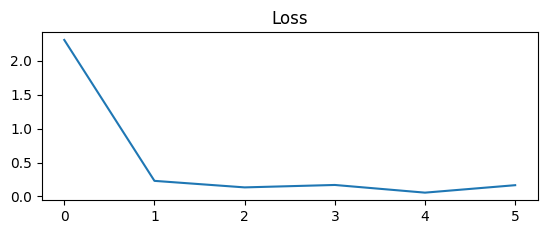

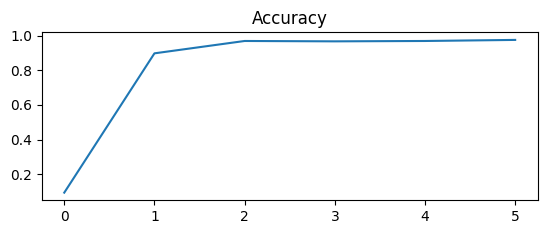

In [9]:
#调用
epoch = 3
Loss = []
Accuracy = []

for epoch in range(1, epoch+1):
    print("start_time",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())))
    loss, acc = train_runner(model, device, trainloader, optimizer, epoch)
    Loss.append(loss)
    Accuracy.append(acc)
    test_runner(model, device, testloader)
    print("end_time: ",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())),'\n')

print('Finished Training')
plt.subplot(2,1,1)
plt.plot(Loss)
plt.title('Loss')
plt.show()
plt.subplot(2,1,2)
plt.plot(Accuracy)
plt.title('Accuracy')
plt.show()

## 1.7 保存模型

In [11]:
# print(model)

import os

os.makedirs('../../outputs', exist_ok=True)
torch.save(model, '../../outputs/model-mnist.pth') #保存模型

## 1.8 手写图片的测试

利用刚刚训练的模型进行手写图片的测试。

In [12]:
# !pip install opencv-python

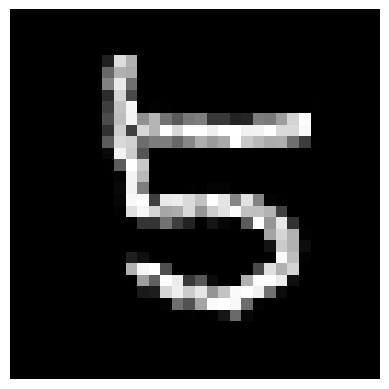

概率： tensor([[9.3281e-08, 3.9592e-08, 1.3816e-04, 2.8669e-05, 1.3877e-08, 9.9982e-01,
         1.2173e-06, 6.1464e-06, 1.2463e-07, 2.0586e-06]], device='mps:0',
       grad_fn=<SoftmaxBackward0>)
预测类别： 5


In [13]:
import cv2

if __name__ == '__main__':
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    model = torch.load('../../outputs/model-mnist.pth', weights_only=False) #加载模型
    # model = torch.load('../../outputs/model-mnist-epoch-2.pth') #加载模型
    model = model.to(device)
    model.eval()    #把模型转为test模式
    
    #读取要预测的图片
    img = cv2.imread("../../assets/lenet-7.jpg")
    img=cv2.resize(img,dsize=(32,32),interpolation=cv2.INTER_NEAREST)
    plt.imshow(img,cmap="gray") # 显示图片
    plt.axis('off') # 不显示坐标轴
    plt.show()
    
    # 导入图片，图片扩展后为[1，1，32，32]
    trans = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)#图片转为灰度图，因为mnist数据集都是灰度图
    img = trans(img)
    img = img.to(device)
    img = img.unsqueeze(0)  #图片扩展多一维,因为输入到保存的模型中是4维的[batch_size,通道,长，宽]，而普通图片只有三维，[通道,长，宽]
    
    # 预测 
    #output = model(img)
    #predict = output.argmax(dim=1)
    #print(predict.item())
    
    
    
    # 预测 
    output = model(img)
    prob = F.softmax(output,dim=1) #prob是10个分类的概率
    print("概率：",prob)
    value, predicted = torch.max(output.data, 1)
    predict = output.argmax(dim=1)
    print("预测类别：",predict.item())

## 1.9 炫酷版本


                  LeNet-5 Training System                   

System Information:
  ▸ Date:        2026-04-26 13:53:45
  ▸ Platform:    darwin
  ▸ PyTorch:     2.8.0
  ▸ CUDA:        Not Available ❌

Training Configuration:
  ▸ Model:       LeNet-5
  ▸ Optimizer:   Adam
  ▸ LR:          0.001
  ▸ Batch Size:  Train: 64, Test: 32
  ▸ Epochs:       3
  ▸ Save Dir:     ./models/

──────────────────────────────────────────────────
[INFO] Created directory: ./models/lenet_mnist
[INFO] Created directory: ./models/lenet_mnist/checkpoints
[INFO] Created directory: ./models/lenet_mnist/best_model
[INFO] Created directory: ./models/lenet_mnist/final_model

▶ Model Architecture
LeNet-5 Architecture:
  Layer                Output Shape         Param #   
  ──────────────────── ──────────────────── ──────────
  Conv1                6@28x28              156       
  ReLU                 6@28x28              0         
  MaxPool1             6@14x14              0         
  Conv2                16@

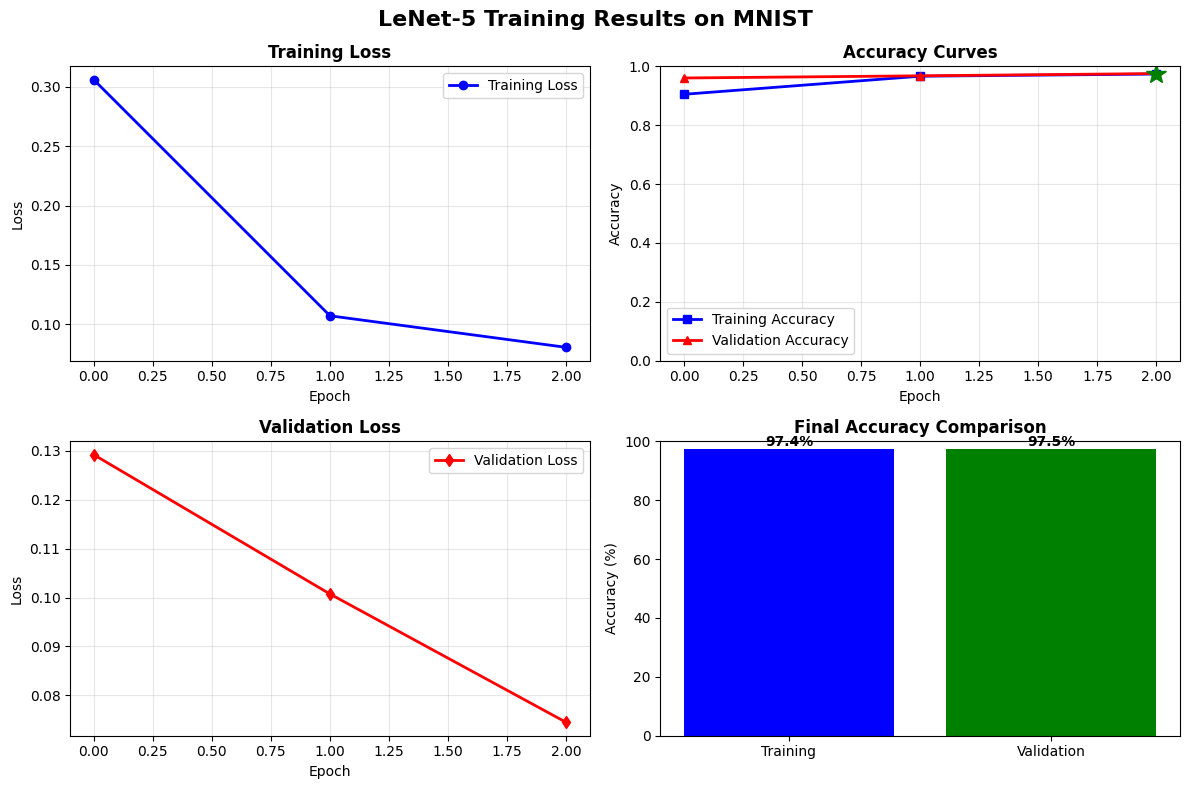

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time
import sys
import os
import numpy as np
from datetime import datetime
from torchvision import datasets, transforms
import shutil
from matplotlib import pyplot as plt

# 添加颜色和样式定义
class Colors:
    """ANSI颜色代码"""
    HEADER = '\033[95m'
    BLUE = '\033[94m'
    CYAN = '\033[96m'
    GREEN = '\033[92m'
    YELLOW = '\033[93m'
    RED = '\033[91m'
    BOLD = '\033[1m'
    UNDERLINE = '\033[4m'
    END = '\033[0m'
    GRAY = '\033[90m'
    ORANGE = '\033[33m'
    PURPLE = '\033[35m'

class PrintStyle:
    """打印格式样式"""
    @staticmethod
    def banner(text):
        """横幅样式"""
        width = 60
        print("\n" + "="*width)
        print(f"{Colors.PURPLE}{Colors.BOLD}{text:^{width}}{Colors.END}")
        print("="*width)
    
    @staticmethod
    def section_header(text):
        """章节标题"""
        print(f"\n{Colors.BLUE}{Colors.BOLD}▶ {text}{Colors.END}")
    
    @staticmethod
    def info(text):
        """信息样式"""
        print(f"{Colors.CYAN}[INFO]{Colors.END} {text}")
    
    @staticmethod
    def success(text):
        """成功样式"""
        print(f"{Colors.GREEN}[SUCCESS]{Colors.END} {text}")
    
    @staticmethod
    def warning(text):
        """警告样式"""
        print(f"{Colors.YELLOW}[WARNING]{Colors.END} {text}")
    
    @staticmethod
    def error(text):
        """错误样式"""
        print(f"{Colors.RED}[ERROR]{Colors.END} {text}")
    
    @staticmethod
    def progress_bar(iteration, total, prefix='', suffix='', length=50, fill='█'):
        """进度条"""
        percent = ("{0:.1f}").format(100 * (iteration / float(total)))
        filled_length = int(length * iteration // total)
        bar = fill * filled_length + '-' * (length - filled_length)
        
        sys.stdout.write(f'\r{prefix} |{Colors.GREEN}{bar}{Colors.END}| {percent}% {suffix}')
        sys.stdout.flush()
        
        if iteration == total:
            print()

# 模型保存管理器
class ModelSaver:
    """模型保存管理器"""
    def __init__(self, base_dir="../../outputs", model_name="lenet_mnist"):
        """
        初始化模型保存器
        
        Args:
            base_dir: 模型保存的基础目录
            model_name: 模型名称前缀
        """
        self.base_dir = base_dir
        self.model_name = model_name
        self.models_dir = os.path.join(base_dir, model_name)
        self.best_accuracy = 0.0
        self.best_epoch = 0
        self.best_model_path = None
        
        # 创建模型保存目录
        self._create_directories()
        
    def _create_directories(self):
        """创建必要的目录结构"""
        dirs_to_create = [
            self.base_dir,
            self.models_dir,
            os.path.join(self.models_dir, "checkpoints"),
            os.path.join(self.models_dir, "best_model"),
            os.path.join(self.models_dir, "final_model"),
        ]
        
        for dir_path in dirs_to_create:
            if not os.path.exists(dir_path):
                os.makedirs(dir_path)
                PrintStyle.info(f"Created directory: {dir_path}")
            else:
                # 清空best_model目录
                if "best_model" in dir_path:
                    for file in os.listdir(dir_path):
                        file_path = os.path.join(dir_path, file)
                        try:
                            if os.path.isfile(file_path):
                                os.unlink(file_path)
                        except Exception as e:
                            PrintStyle.warning(f"Failed to delete {file_path}: {e}")
    
    def save_checkpoint(self, model, optimizer, epoch, train_loss, train_acc, val_loss, val_acc, is_best=False):
        """
        保存检查点（包含模型和元数据）
        
        Args:
            model: 要保存的模型
            optimizer: 优化器
            epoch: 当前epoch
            train_loss: 训练损失
            train_acc: 训练准确率
            val_loss: 验证损失
            val_acc: 验证准确率
            is_best: 是否为最佳模型
        """
        # 1. 保存模型检查点（包含元数据）
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'val_loss': val_loss,
            'val_accuracy': val_acc,
            'timestamp': datetime.now().strftime('%Y-%m-%d_%H-%M-%S'),
            'best_epoch': self.best_epoch,
            'best_accuracy': self.best_accuracy
        }
        
        checkpoint_path = os.path.join(
            self.models_dir, 
            "checkpoints", 
            f"{self.model_name}_epoch_{epoch:03d}_checkpoint.pth"
        )
        torch.save(checkpoint, checkpoint_path)
        PrintStyle.success(f"Saved checkpoint for epoch {epoch} to {checkpoint_path}")
        
        # 2. 保存纯模型文件（用于直接加载）
        model_path = os.path.join(
            self.models_dir, 
            "checkpoints", 
            f"{self.model_name}_epoch_{epoch:03d}_model.pth"
        )
        torch.save(model, model_path)
        PrintStyle.info(f"Saved model file for epoch {epoch}")
        
        # 3. 如果是最佳模型，保存到best_model文件夹
        if is_best:
            # 清空best_model文件夹
            best_model_dir = os.path.join(self.models_dir, "best_model")
            for file in os.listdir(best_model_dir):
                file_path = os.path.join(best_model_dir, file)
                if os.path.isfile(file_path) and file.endswith('.pth'):
                    os.remove(file_path)
            
            # 保存最佳模型文件（可以直接torch.load的模型）
            self.best_model_path = os.path.join(
                best_model_dir,
                f"{self.model_name}_best_epoch_{epoch:03d}_acc_{val_acc*100:.2f}.pth"
            )
            # 保存模型本身，而不是检查点
            torch.save(model, self.best_model_path)
            
            # 同时保存一个检查点版本（用于恢复训练）
            best_checkpoint_path = os.path.join(
                best_model_dir,
                f"{self.model_name}_best_epoch_{epoch:03d}_acc_{val_acc*100:.2f}_checkpoint.pth"
            )
            torch.save(checkpoint, best_checkpoint_path)
            
            PrintStyle.success(f"🏆 Best model saved! Accuracy: {val_acc*100:.2f}% (epoch {epoch})")
            PrintStyle.info(f"   Model file: {os.path.basename(self.best_model_path)}")
            PrintStyle.info(f"   Checkpoint file: {os.path.basename(best_checkpoint_path)}")
    
    def save_final_model(self, model, optimizer, train_losses, train_accuracies, val_losses, val_accuracies):
        """
        保存最终模型和训练历史
        
        Args:
            model: 最终模型
            optimizer: 优化器
            train_losses: 训练损失历史
            train_accuracies: 训练准确率历史
            val_losses: 验证损失历史
            val_accuracies: 验证准确率历史
        """
        # 保存最终模型文件（可以直接torch.load的模型）
        final_model_path = os.path.join(
            self.models_dir,
            "final_model",
            f"{self.model_name}_final.pth"
        )
        torch.save(model, final_model_path)
        
        # 保存最终检查点（包含训练历史）
        final_checkpoint = {
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_losses': train_losses,
            'train_accuracies': train_accuracies,
            'val_losses': val_losses,
            'val_accuracies': val_accuracies,
            'best_epoch': self.best_epoch,
            'best_accuracy': self.best_accuracy,
            'final_epoch': len(train_losses),
            'final_train_accuracy': train_accuracies[-1] if train_accuracies else 0,
            'final_val_accuracy': val_accuracies[-1] if val_accuracies else 0,
            'timestamp': datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
        }
        
        final_checkpoint_path = os.path.join(
            self.models_dir,
            "final_model",
            f"{self.model_name}_final_checkpoint.pth"
        )
        torch.save(final_checkpoint, final_checkpoint_path)
        
        PrintStyle.success(f"Final model saved to {final_model_path}")
        PrintStyle.success(f"Final checkpoint saved to {final_checkpoint_path}")
        
        # 保存训练历史为CSV格式
        self._save_training_history(train_losses, train_accuracies, val_losses, val_accuracies)
        
        # 保存模型摘要
        self._save_model_summary(model, train_losses, train_accuracies, val_losses, val_accuracies)
    
    def _save_training_history(self, train_losses, train_accuracies, val_losses, val_accuracies):
        """保存训练历史为CSV格式"""
        import csv
        
        history_path = os.path.join(self.models_dir, "training_history.csv")
        
        with open(history_path, 'w', newline='') as csvfile:
            writer = csv.writer(csvfile)
            writer.writerow(['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])
            
            for epoch in range(len(train_losses)):
                writer.writerow([
                    epoch + 1,
                    train_losses[epoch],
                    train_accuracies[epoch],
                    val_losses[epoch],
                    val_accuracies[epoch]
                ])
        
        PrintStyle.info(f"Training history saved to {history_path}")
    
    def _save_model_summary(self, model, train_losses, train_accuracies, val_losses, val_accuracies):
        """保存模型训练摘要"""
        summary_path = os.path.join(self.models_dir, "training_summary.txt")
        
        with open(summary_path, 'w') as f:
            f.write("="*60 + "\n")
            f.write("LeNet-5 MNIST Training Summary\n")
            f.write("="*60 + "\n\n")
            
            f.write(f"Training Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
            f.write(f"Model Name: {self.model_name}\n")
            f.write(f"Total Epochs: {len(train_losses)}\n")
            f.write(f"Best Epoch: {self.best_epoch}\n")
            f.write(f"Best Validation Accuracy: {self.best_accuracy*100:.2f}%\n")
            f.write(f"Final Training Accuracy: {train_accuracies[-1]*100:.2f}%\n")
            f.write(f"Final Validation Accuracy: {val_accuracies[-1]*100:.2f}%\n\n")
            
            f.write("-"*60 + "\n")
            f.write("Training History:\n")
            f.write("-"*60 + "\n")
            f.write(f"{'Epoch':<6} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}\n")
            f.write("-"*60 + "\n")
            
            for epoch in range(len(train_losses)):
                f.write(f"{epoch+1:<6} "
                       f"{train_losses[epoch]:<12.6f} "
                       f"{train_accuracies[epoch]*100:<12.2f}% "
                       f"{val_losses[epoch]:<12.6f} "
                       f"{val_accuracies[epoch]*100:<12.2f}%\n")
        
        PrintStyle.info(f"Training summary saved to {summary_path}")
    
    def update_best_model(self, val_acc, epoch):
        """
        更新最佳模型信息
        
        Args:
            val_acc: 当前验证准确率
            epoch: 当前epoch
        
        Returns:
            bool: 如果当前模型是最佳模型则返回True
        """
        if val_acc > self.best_accuracy:
            self.best_accuracy = val_acc
            self.best_epoch = epoch
            return True
        return False
    
    def load_model(self, model_path):
        """
        直接加载模型文件
        
        Args:
            model_path: 模型文件路径
        
        Returns:
            model: 加载的模型
        """
        if not os.path.exists(model_path):
            PrintStyle.error(f"Model file not found: {model_path}")
            return None
        
        try:
            model = torch.load(model_path)
            PrintStyle.success(f"Loaded model from {model_path}")
            return model
        except Exception as e:
            PrintStyle.error(f"Failed to load model: {e}")
            return None
    
    def load_checkpoint(self, checkpoint_path, model, optimizer=None):
        """
        加载检查点（用于恢复训练）
        
        Args:
            checkpoint_path: 检查点文件路径
            model: 要加载权重的模型
            optimizer: 要加载状态的优化器（可选）
        
        Returns:
            dict: 加载的检查点信息
        """
        if not os.path.exists(checkpoint_path):
            PrintStyle.error(f"Checkpoint not found: {checkpoint_path}")
            return None
        
        checkpoint = torch.load(checkpoint_path)
        
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
            if optimizer is not None and 'optimizer_state_dict' in checkpoint:
                optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            PrintStyle.success(f"Loaded checkpoint from epoch {checkpoint.get('epoch', 'unknown')}")
            return checkpoint
        else:
            PrintStyle.warning("Checkpoint format not recognized. Trying to load as model...")
            return checkpoint
    
    def get_best_model_info(self):
        """获取最佳模型文件信息"""
        best_model_dir = os.path.join(self.models_dir, "best_model")
        best_files = []
        
        if os.path.exists(best_model_dir):
            for file in os.listdir(best_model_dir):
                if file.endswith('.pth') and 'checkpoint' not in file:
                    best_files.append(os.path.join(best_model_dir, file))
        
        if best_files:
            # 按epoch编号排序，返回最后一个（最高的epoch）
            best_files.sort(key=lambda x: int(x.split('epoch_')[1].split('_')[0]) if 'epoch_' in x else 0)
            return best_files[-1]
        return None

# 定义训练集的数据预处理管道
pipline_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))    
])

# 定义测试集的数据预处理管道
pipline_test = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# 下载并加载MNIST数据集
train_set = datasets.MNIST(
    root="../../data",
    train=True,
    download=True,
    transform=pipline_train
)

test_set = datasets.MNIST(
    root="../../data",
    train=False,
    download=True,
    transform=pipline_test
)

# 创建数据加载器
trainloader = torch.utils.data.DataLoader(
    train_set,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

testloader = torch.utils.data.DataLoader(
    test_set,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# LeNet模型定义
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.relu = nn.ReLU()
        self.maxpool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.maxpool2 = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
 
    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        output = F.log_softmax(x, dim=1)
        return output

def train_runner(model, device, trainloader, optimizer, epoch, total_epochs):
    """训练函数"""
    model.train()
    total = 0
    correct = 0.0
    total_batches = len(trainloader)
    running_loss = 0.0
    
    PrintStyle.section_header(f"Epoch {epoch}/{total_epochs}")
    
    for i, data in enumerate(trainloader, 0):
        batch_start = time.time()
        
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = F.cross_entropy(outputs, labels)
        
        predict = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predict == labels).sum().item()
        running_loss += loss.item()
        
        loss.backward()
        optimizer.step()
        
        # 进度条更新
        if i % 100 == 0 or i == total_batches - 1:
            accuracy = correct / total
            avg_loss = running_loss / (i + 1)
            prefix = f"{Colors.BOLD}Batch {i+1:4d}/{total_batches}{Colors.END}"
            suffix = f"Loss: {loss.item():.4f} | Acc: {100*accuracy:6.2f}%"
            PrintStyle.progress_bar(i+1, total_batches, prefix, suffix)
    
    accuracy = correct / total
    avg_loss = running_loss / total_batches
    
    # 显示epoch结果
    print(f"\n{Colors.GREEN}{'━'*50}{Colors.END}")
    print(f"{Colors.BOLD}📊 Epoch {epoch} Summary:{Colors.END}")
    print(f"  {Colors.CYAN}● Average Loss:{Colors.END} {Colors.BOLD}{avg_loss:.6f}{Colors.END}")
    print(f"  {Colors.GREEN}● Training Accuracy:{Colors.END} {Colors.BOLD}{100*accuracy:.2f}%{Colors.END}")
    print(f"{Colors.GREEN}{'━'*50}{Colors.END}\n")
    
    return avg_loss, accuracy

def test_runner(model, device, testloader):
    """测试函数"""
    model.eval()
    correct = 0.0
    test_loss = 0.0
    total = 0
    
    PrintStyle.info("Running validation...")
    
    with torch.no_grad():
        for batch_idx, (data, label) in enumerate(testloader):
            data, label = data.to(device), label.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, label, reduction='sum').item()
            predict = output.argmax(dim=1)
            total += label.size(0)
            correct += (predict == label).sum().item()
            
            # 每100个batch显示一次进度
            if batch_idx % 100 == 0:
                PrintStyle.progress_bar(batch_idx, len(testloader), 
                                      f"{Colors.CYAN}Validating{Colors.END}", "")
    
    avg_loss = test_loss / total
    accuracy = correct / total
    
    # 结果表格
    print(f"\n{Colors.BLUE}{'═'*60}{Colors.END}")
    print(f"{Colors.BOLD}{Colors.PURPLE}📈 Validation Results{Colors.END}")
    print(f"{Colors.BLUE}{'─'*60}{Colors.END}")
    
    print(f"{Colors.CYAN}┌{'─'*25}┬{'─'*30}┐{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Metric':^24}{Colors.CYAN}│{Colors.END}{'Value':^29}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}├{'─'*25}┼{'─'*30}┤{Colors.END}")
    
    # 根据准确率显示不同颜色
    accuracy_color = Colors.GREEN if accuracy > 0.9 else Colors.YELLOW if accuracy > 0.8 else Colors.RED
    loss_color = Colors.RED if avg_loss > 0.5 else Colors.YELLOW if avg_loss > 0.1 else Colors.GREEN
    
    print(f"{Colors.CYAN}│{Colors.END}{'Test Loss':<24}{Colors.CYAN}│{Colors.END} {loss_color}{avg_loss:>8.6f}{Colors.END}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Test Accuracy':<24}{Colors.CYAN}│{Colors.END} {accuracy_color}{accuracy*100:>7.2f}%{Colors.END}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Correct/Total':<24}{Colors.CYAN}│{Colors.END} {correct:>5.0f}/{total:<5.0f}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}└{'─'*25}┴{'─'*30}┘{Colors.END}")
    print(f"{Colors.BLUE}{'═'*60}{Colors.END}\n")
    
    return avg_loss, accuracy

def print_system_info():
    """打印系统信息"""
    PrintStyle.banner("LeNet-5 Training System")
    
    print(f"\n{Colors.BOLD}System Information:{Colors.END}")
    print(f"  {Colors.CYAN}▸ Date:{Colors.END}        {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"  {Colors.CYAN}▸ Platform:{Colors.END}    {sys.platform}")
    print(f"  {Colors.CYAN}▸ PyTorch:{Colors.END}     {torch.__version__}")
    print(f"  {Colors.CYAN}▸ CUDA:{Colors.END}        {'Available ✅' if torch.cuda.is_available() else 'Not Available ❌'}")
    
    if torch.cuda.is_available():
        print(f"  {Colors.CYAN}▸ GPU:{Colors.END}         {torch.cuda.get_device_name(0)}")
        print(f"  {Colors.CYAN}▸ CUDA Version:{Colors.END} {torch.version.cuda}")
    
    print(f"\n{Colors.BOLD}Training Configuration:{Colors.END}")
    print(f"  {Colors.GREEN}▸ Model:{Colors.END}       LeNet-5")
    print(f"  {Colors.GREEN}▸ Optimizer:{Colors.END}   Adam")
    print(f"  {Colors.GREEN}▸ LR:{Colors.END}          0.001")
    print(f"  {Colors.GREEN}▸ Batch Size:{Colors.END}  Train: 64, Test: 32")
    print(f"  {Colors.GREEN}▸ Epochs:{Colors.END}       3")
    print(f"  {Colors.GREEN}▸ Save Dir:{Colors.END}     ../../outputs/")
    print(f"\n{Colors.YELLOW}{'─'*50}{Colors.END}")

def print_model_summary(model):
    """打印模型摘要"""
    PrintStyle.section_header("Model Architecture")
    
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    print(f"{Colors.CYAN}LeNet-5 Architecture:{Colors.END}")
    print(f"  {'Layer':<20} {'Output Shape':<20} {'Param #':<10}")
    print(f"  {'─'*20} {'─'*20} {'─'*10}")
    
    layers_info = [
        ("Conv1", "6@28x28", "156"),
        ("ReLU", "6@28x28", "0"),
        ("MaxPool1", "6@14x14", "0"),
        ("Conv2", "16@10x10", "2,416"),
        ("MaxPool2", "16@5x5", "0"),
        ("Flatten", "400", "0"),
        ("FC1", "120", "48,120"),
        ("FC2", "84", "10,164"),
        ("FC3", "10", "850")
    ]
    
    for layer, shape, params in layers_info:
        print(f"  {Colors.BLUE}{layer:<20}{Colors.END} {shape:<20} {params:<10}")
    
    print(f"\n{Colors.GREEN}Total params:{Colors.END} {total_params:,}")
    print(f"{Colors.GREEN}Trainable params:{Colors.END} {trainable_params:,}")
    print(f"{Colors.GREEN}Non-trainable params:{Colors.END} {total_params - trainable_params:,}")
    print(f"{Colors.YELLOW}{'─'*50}{Colors.END}")

# 主训练循环
def main():
    # 清除屏幕
    os.system('cls' if os.name == 'nt' else 'clear')
    
    # 打印系统信息
    print_system_info()
    
    # 创建模型保存器
    model_saver = ModelSaver(base_dir="../../outputs", model_name="lenet_mnist")
    
    # 创建模型
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    model = LeNet().to(device)
    
    # 打印模型信息
    print_model_summary(model)
    
    # 定义优化器
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    # 训练参数
    epochs = 3
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []
    
    PrintStyle.banner("Starting Training")
    
    for epoch in range(1, epochs + 1):
        epoch_start_time = time.time()
        
        # 训练
        train_loss, train_acc = train_runner(model, device, trainloader, optimizer, epoch, epochs)
        train_losses.append(train_loss)
        train_accuracies.append(train_acc)
        
        # 测试
        val_loss, val_acc = test_runner(model, device, testloader)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        
        # 更新最佳模型并检查是否为最佳
        is_best = model_saver.update_best_model(val_acc, epoch)
        
        # 保存检查点
        model_saver.save_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            train_loss=train_loss,
            train_acc=train_acc,
            val_loss=val_loss,
            val_acc=val_acc,
            is_best=is_best
        )
        
        epoch_time = time.time() - epoch_start_time
        
        # 打印epoch总结
        PrintStyle.section_header(f"Epoch {epoch} Complete")
        print(f"{Colors.GREEN}✅ Training completed in {epoch_time:.2f} seconds{Colors.END}")
        print(f"{Colors.CYAN}📈 Training Acc: {train_acc*100:.2f}% | Validation Acc: {val_acc*100:.2f}%{Colors.END}")
        
        if is_best:
            print(f"{Colors.GREEN}🌟 New best model! Accuracy: {val_acc*100:.2f}%{Colors.END}")
        
        if val_acc > 0.95:
            PrintStyle.success("Excellent accuracy achieved! 🎉")
        elif val_acc > 0.9:
            PrintStyle.success("Great performance! ✨")
        elif val_acc > 0.85:
            PrintStyle.info("Good performance! Keep going! 💪")
        else:
            PrintStyle.warning("Accuracy can be improved. Try adjusting hyperparameters. 🔧")
    
    # 保存最终模型
    model_saver.save_final_model(model, optimizer, train_losses, train_accuracies, val_losses, val_accuracies)
    
    # 最终总结
    PrintStyle.banner("Training Complete!")
    
    best_epoch = model_saver.best_epoch
    best_acc = model_saver.best_accuracy * 100
    
    print(f"\n{Colors.BOLD}🎯 Training Summary:{Colors.END}")
    print(f"  {Colors.GREEN}● Total Epochs:{Colors.END}        {epochs}")
    print(f"  {Colors.GREEN}● Best Epoch:{Colors.END}          {best_epoch}")
    print(f"  {Colors.GREEN}● Best Validation Acc:{Colors.END}  {best_acc:.2f}%")
    print(f"  {Colors.GREEN}● Final Training Acc:{Colors.END}   {train_accuracies[-1]*100:.2f}%")
    print(f"  {Colors.GREEN}● Final Validation Acc:{Colors.END} {val_accuracies[-1]*100:.2f}%")
    
    # 打印模型保存信息
    PrintStyle.section_header("Model Files Saved")
    
    # 获取最佳模型文件
    best_model_path = model_saver.get_best_model_info()
    if best_model_path and os.path.exists(best_model_path):
        filename = os.path.basename(best_model_path)
        print(f"{Colors.GREEN}✅ Best Model File:{Colors.END}   {filename}")
        print(f"  - Path: {best_model_path}")
        print(f"  - Can be loaded directly with torch.load()")
    else:
        print(f"{Colors.YELLOW}⚠️  Best model not found{Colors.END}")
    
    print(f"\n{Colors.CYAN}Directory Structure:{Colors.END}")
    print(f"  {Colors.BLUE}● checkpoints/{Colors.END}")
    print(f"    - {Colors.GRAY}lenet_mnist_epoch_XXX_model.pth{Colors.END} (直接可用的模型文件)")
    print(f"    - {Colors.GRAY}lenet_mnist_epoch_XXX_checkpoint.pth{Colors.END} (包含训练信息的检查点)")
    print(f"  {Colors.BLUE}● best_model/{Colors.END}")
    print(f"    - {Colors.GRAY}lenet_mnist_best_epoch_XXX_acc_XX.XX.pth{Colors.END} (最佳模型，可直接加载)")
    print(f"  {Colors.BLUE}● final_model/{Colors.END}")
    print(f"    - {Colors.GRAY}lenet_mnist_final.pth{Colors.END} (最终模型)")
    print(f"  {Colors.BLUE}● training_history.csv{Colors.END}")
    print(f"    - 训练历史数据")
    print(f"  {Colors.BLUE}● training_summary.txt{Colors.END}")
    print(f"    - 训练摘要")
    
    if best_acc > 99:
        print(f"\n{Colors.GREEN}{Colors.BOLD}🏆 Outstanding performance! Model is ready for deployment!{Colors.END}")
    elif best_acc > 98:
        print(f"\n{Colors.GREEN}{Colors.BOLD}✨ Excellent results! Model performance is outstanding!{Colors.END}")
    elif best_acc > 97:
        print(f"\n{Colors.GREEN}{Colors.BOLD}👍 Great job! Model is performing very well!{Colors.END}")
    elif best_acc > 95:
        print(f"\n{Colors.YELLOW}{Colors.BOLD}✓ Good performance! Model is learning well!{Colors.END}")
    else:
        print(f"\n{Colors.RED}{Colors.BOLD}⚠️ Consider training for more epochs or adjusting hyperparameters.{Colors.END}")
    
    # 显示最佳模型的使用方法
    PrintStyle.section_header("How to Load and Use the Model")
    if best_model_path:
        print(f"{Colors.CYAN}Method 1 - Direct loading (recommended):{Colors.END}")
        print(f"{Colors.GRAY}import torch{Colors.END}")
        print(f"{Colors.GRAY}import cv2{Colors.END}")
        print(f"{Colors.GRAY}from torchvision import transforms{Colors.END}")
        print(f"\n{Colors.GRAY}# Load model directly{Colors.END}")
        print(f"{Colors.GRAY}model = torch.load('{best_model_path}'){Colors.END}")
        print(f"{Colors.GRAY}model.eval(){Colors.END}")
        print(f"\n{Colors.GRAY}# Use the model for inference{Colors.END}")
        print(f"{Colors.GRAY}# ... your inference code ...{Colors.END}")
        
        print(f"\n{Colors.CYAN}Method 2 - Load checkpoint (for resuming training):{Colors.END}")
        print(f"{Colors.GRAY}checkpoint = torch.load('{best_model_path.replace('.pth', '_checkpoint.pth') if os.path.exists(best_model_path.replace('.pth', '_checkpoint.pth')) else best_model_path}'){Colors.END}")
        print(f"{Colors.GRAY}model = LeNet()  # Create new model instance{Colors.END}")
        print(f"{Colors.GRAY}model.load_state_dict(checkpoint['model_state_dict']){Colors.END}")
    
    print(f"\n{Colors.PURPLE}{'='*50}{Colors.END}")
    print(f"{Colors.BOLD}Training session completed at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}{Colors.END}")
    print(f"{Colors.PURPLE}{'='*50}{Colors.END}")
    
    # 绘制训练曲线
    try:
        import matplotlib.pyplot as plt
        
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        
        # 训练损失
        axes[0, 0].plot(train_losses, 'b-', linewidth=2, marker='o', label='Training Loss')
        axes[0, 0].set_title('Training Loss', fontsize=12, fontweight='bold')
        axes[0, 0].set_xlabel('Epoch')
        axes[0, 0].set_ylabel('Loss')
        axes[0, 0].grid(True, alpha=0.3)
        axes[0, 0].legend()
        
        # 准确率曲线
        axes[0, 1].plot(train_accuracies, 'b-', linewidth=2, marker='s', label='Training Accuracy')
        axes[0, 1].plot(val_accuracies, 'r-', linewidth=2, marker='^', label='Validation Accuracy')
        axes[0, 1].set_title('Accuracy Curves', fontsize=12, fontweight='bold')
        axes[0, 1].set_xlabel('Epoch')
        axes[0, 1].set_ylabel('Accuracy')
        axes[0, 1].set_ylim(0, 1.0)
        axes[0, 1].grid(True, alpha=0.3)
        axes[0, 1].legend()
        
        # 标记最佳准确率
        best_idx = best_epoch - 1
        if 0 <= best_idx < len(val_accuracies):
            axes[0, 1].plot(best_idx, val_accuracies[best_idx], 'g*', markersize=15, 
                          label=f'Best: {val_accuracies[best_idx]*100:.1f}%')
        
        # 验证损失
        axes[1, 0].plot(val_losses, 'r-', linewidth=2, marker='d', label='Validation Loss')
        axes[1, 0].set_title('Validation Loss', fontsize=12, fontweight='bold')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Loss')
        axes[1, 0].grid(True, alpha=0.3)
        axes[1, 0].legend()
        
        # 最终准确率对比
        axes[1, 1].bar(['Training', 'Validation'], 
                      [train_accuracies[-1]*100, val_accuracies[-1]*100], 
                      color=['blue', 'green'])
        axes[1, 1].set_title('Final Accuracy Comparison', fontsize=12, fontweight='bold')
        axes[1, 1].set_ylabel('Accuracy (%)')
        axes[1, 1].set_ylim(0, 100)
        axes[1, 1].text(0, train_accuracies[-1]*100 + 1, f'{train_accuracies[-1]*100:.1f}%', 
                       ha='center', fontweight='bold')
        axes[1, 1].text(1, val_accuracies[-1]*100 + 1, f'{val_accuracies[-1]*100:.1f}%', 
                       ha='center', fontweight='bold')
        
        plt.suptitle('LeNet-5 Training Results on MNIST', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
    except ImportError:
        PrintStyle.warning("matplotlib not installed. Skipping plots.")

if __name__ == "__main__":
    main()

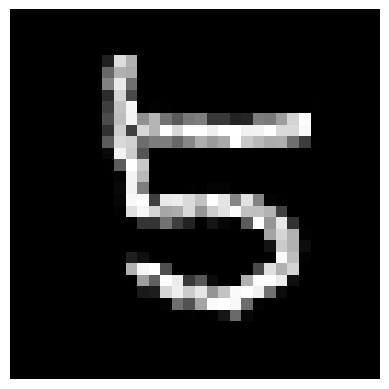

概率： tensor([[3.8952e-05, 1.4540e-05, 7.2398e-03, 9.3901e-03, 1.9408e-06, 9.6877e-01,
         1.2826e-03, 1.6437e-04, 1.3049e-02, 5.2992e-05]],
       grad_fn=<SoftmaxBackward0>)
预测类别： 5


In [20]:
import cv2

if __name__ == '__main__':
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = torch.load('../../outputs/lenet_mnist/final_model/lenet_mnist_final.pth', weights_only=False) #加载模型
    # model = torch.load('../../outputs/model-mnist-epoch-2.pth') #加载模型
    model = model.to(device)
    model.eval()    #把模型转为test模式
    
    #读取要预测的图片
    img = cv2.imread("../../assets/lenet-7.jpg")
    img=cv2.resize(img,dsize=(32,32),interpolation=cv2.INTER_NEAREST)
    plt.imshow(img,cmap="gray") # 显示图片
    plt.axis('off') # 不显示坐标轴
    plt.show()
    
    # 导入图片，图片扩展后为[1，1，32，32]
    trans = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)#图片转为灰度图，因为mnist数据集都是灰度图
    img = trans(img)
    img = img.to(device)
    img = img.unsqueeze(0)  #图片扩展多一维,因为输入到保存的模型中是4维的[batch_size,通道,长，宽]，而普通图片只有三维，[通道,长，宽]
    
    # 预测 
    #output = model(img)
    #predict = output.argmax(dim=1)
    #print(predict.item())
    
    
    
    # 预测 
    output = model(img)
    prob = F.softmax(output,dim=1) #prob是10个分类的概率
    print("概率：",prob)
    value, predicted = torch.max(output.data, 1)
    predict = output.argmax(dim=1)
    print("预测类别：",predict.item())

# 三、用LeNet-5训练自己的数据

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import time
from matplotlib import pyplot as plt

下面使用LeNet-5网络来训练本地的数据并进行测试。数据集是本地的LED数字0-9，尺寸为28x28单通道，跟MNIST数据集类似。训练集0-9各95张，测试集0~9各40张。图片样例如图所示：

![](../../assets/lenet-3.png)

## 3.1 数据预处理 

### 制作图片数据的索引

对于训练集和测试集，要分别制作对应的图片数据索引，即train.txt和test.txt两个文件，每个txt中包含每个图片的目录和对应类别class。示意图如下：

![](../../assets/lenet-2.png)

In [ ]:
# 在线下载慢，可以选择直接拷贝

!cp -r /workspace/DataSet/cvdata/LEDNUM/ ../../data/

制作图片数据索引的python脚本程序如下：

In [ ]:
import os

train_txt_path = os.path.join("../../data", "LEDNUM", "train.txt")
train_dir = os.path.join("../../data", "LEDNUM", "train_data")
valid_txt_path = os.path.join("../../data", "LEDNUM", "test.txt")
valid_dir = os.path.join("../../data", "LEDNUM", "test_data")

def gen_txt(txt_path, img_dir):
    f = open(txt_path, 'w')
    
    for root, s_dirs, _ in os.walk(img_dir, topdown=True):  # 获取 train文件下各文件夹名称
        for sub_dir in s_dirs:
            i_dir = os.path.join(root, sub_dir)             # 获取各类的文件夹 绝对路径
            img_list = os.listdir(i_dir)                    # 获取类别文件夹下所有png图片的路径
            for i in range(len(img_list)):
                if not img_list[i].endswith('jpg'):         # 若不是png文件，跳过
                    continue
                label = img_list[i].split('_')[0]
                img_path = os.path.join(i_dir, img_list[i])
                line = img_path + ' ' + label + '\n'
                f.write(line)
    f.close()

if __name__ == '__main__':
    gen_txt(train_txt_path, train_dir)
    gen_txt(valid_txt_path, valid_dir)

运行脚本之后就在./DataSet/LEDNUM/目录下生成train.txt和test.txt两个索引文件。

### 构建Dataset子类

pytorch 加载自己的数据集，需要写一个继承自torch.utils.data中Dataset类，并修改其中的__init__方法、__getitem__方法、__len__方法。默认加载的都是图片，__init__的目的是得到一个包含数据和标签的list，每个元素能找到图片位置和其对应标签。然后用__getitem__方法得到每个元素的图像像素矩阵和标签，返回img和label。 

In [ ]:
from PIL import Image
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, txt_path, transform = None, target_transform = None):
        fh = open(txt_path, 'r')
        imgs = []
        for line in fh:
            line = line.rstrip()
            words = line.split()
            imgs.append((words[0], int(words[1])))
            self.imgs = imgs 
            self.transform = transform
            self.target_transform = target_transform
    def __getitem__(self, index):
        fn, label = self.imgs[index]
        #img = Image.open(fn).convert('RGB') 
        img = Image.open(fn)
        if self.transform is not None:
            img = self.transform(img) 
        return img, label
    def __len__(self):
        return len(self.imgs)

getitem是核心函数。self.imgs是一个list，self.imgs[index]是一个str，包含图片路径，图片标签，这些信息是从上面生成的txt文件中读取；利用Image.open对图片进行读取，注意这里的img是单通道还是三通道的；self.transform(img)对图片进行处理，这个transform里边可以实现减均值、除标准差、随机裁剪、旋转、翻转、放射变换等操作。

当Mydataset构建好，剩下的操作就交给DataLoder，在DataLoder中，会触发Mydataset中的getiterm函数读取一张图片的数据和标签，并拼接成一个batch返回，作为模型真正的输入。

In [ ]:
pipline_train = transforms.Compose([
    #随机旋转图片
    transforms.RandomHorizontalFlip(),
    #将图片尺寸resize到32x32
    transforms.Resize((32,32)),
    #将图片转化为Tensor格式
    transforms.ToTensor(),
    #正则化(当模型出现过拟合的情况时，用来降低模型的复杂度)
    transforms.Normalize((0.1307,),(0.3081,))    
])
pipline_test = transforms.Compose([
    #将图片尺寸resize到32x32
    transforms.Resize((32,32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,),(0.3081,))
])
train_data = MyDataset('../../data/LEDNUM/train.txt', transform=pipline_train)
test_data = MyDataset('../../data/LEDNUM/test.txt', transform=pipline_test)

#train_data 和test_data包含多有的训练与测试数据，调用DataLoader批量加载
trainloader = torch.utils.data.DataLoader(dataset=train_data, batch_size=8, shuffle=True)
testloader = torch.utils.data.DataLoader(dataset=test_data, batch_size=4, shuffle=False)

## 3.2 搭建LeNet-5神经网络结构

In [ ]:
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5) 
        self.relu = nn.ReLU()
        self.maxpool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.maxpool2 = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
 
    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = x.view(-1, 16*5*5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        output = F.log_softmax(x, dim=1)
        return output

## 3.3 将定义好的网络结构搭载到GPU/CPU，并定义优化器

In [ ]:
#创建模型，部署gpu
if torch.cuda.is_available():
    device = torch.device("cuda:0")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

model = LeNet().to(device)
#定义优化器
optimizer = optim.Adam(model.parameters(), lr=0.001)

## 3.4 定义训练函数

In [ ]:
def train_runner(model, device, trainloader, optimizer, epoch):
    #训练模型, 启用 BatchNormalization 和 Dropout, 将BatchNormalization和Dropout置为True
    model.train()
    total = 0
    correct =0.0
    
    #enumerate迭代已加载的数据集,同时获取数据和数据下标
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        #把模型部署到device上
        inputs, labels = inputs.to(device), labels.to(device)
        #初始化梯度
        optimizer.zero_grad()
        #保存训练结果
        outputs = model(inputs)
        #计算损失和
        #多分类情况通常使用cross_entropy(交叉熵损失函数), 而对于二分类问题, 通常使用sigmod
        loss = F.cross_entropy(outputs, labels)
        #获取最大概率的预测结果
        #dim=1表示返回每一行的最大值对应的列下标
        predict = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predict == labels).sum().item()
        #反向传播
        loss.backward()
        #更新参数
        optimizer.step()
        if i % 100 == 0:
            #loss.item()表示当前loss的数值
            print("Train Epoch{} \t Loss: {:.6f}, accuracy: {:.6f}%".format(epoch, loss.item(), 100*(correct/total)))
            Loss.append(loss.item())
            Accuracy.append(correct/total)
    return loss.item(), correct/total

## 3.5 定义测试函数

In [ ]:
def test_runner(model, device, testloader):
    #模型验证, 必须要写, 否则只要有输入数据, 即使不训练, 它也会改变权值
    #因为调用eval()将不启用 BatchNormalization 和 Dropout, BatchNormalization和Dropout置为False
    model.eval()
    #统计模型正确率, 设置初始值
    correct = 0.0
    test_loss = 0.0
    total = 0
    #torch.no_grad将不会计算梯度, 也不会进行反向传播
    with torch.no_grad():
        for data, label in testloader:
            data, label = data.to(device), label.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, label).item()
            predict = output.argmax(dim=1)
            #计算正确数量
            total += label.size(0)
            correct += (predict == label).sum().item()
        #计算损失值
        print("test_avarage_loss: {:.6f}, accuracy: {:.6f}%".format(test_loss/total, 100*(correct/total)))

## 3.6 运行

In [ ]:
#调用
epoch = 5
Loss = []
Accuracy = []
for epoch in range(1, epoch+1):
    print("start_time",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())))
    loss, acc = train_runner(model, device, trainloader, optimizer, epoch)
    Loss.append(loss)
    Accuracy.append(acc)
    test_runner(model, device, testloader)
    print("end_time: ",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())),'\n')

print('Finished Training')
plt.subplot(2,1,1)
plt.plot(Loss)
plt.title('Loss')
plt.show()
plt.subplot(2,1,2)
plt.plot(Accuracy)
plt.title('Accuracy')
plt.show()

## 3.7 模型保存

In [ ]:
model
torch.save(model, '../../outputs/model-lenet-mine.pth') #保存模型

## 3.8 模型测试

下面使用上面训练的模型对一张LED图片进行测试。

In [ ]:
from PIL import Image
import numpy as np

if __name__ == '__main__':
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    model = torch.load('../../outputs/model-lenet-mine.pth', weights_only=False) #加载模型
    model = model.to(device)
    model.eval()    #把模型转为test模式
    
    #读取要预测的图片
    # 读取要预测的图片
    img = Image.open("../../assets/lenet-6.jpg") # 读取图像
    #img.show()
    plt.imshow(img,cmap="gray") # 显示图片
    plt.axis('off') # 不显示坐标轴
    plt.show()
    
    # 导入图片，图片扩展后为[1，1，32，32]
    trans = transforms.Compose(
        [
            #将图片尺寸resize到32x32
            transforms.Resize((32,32)),
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])
    img = trans(img)
    img = img.to(device)
    img = img.unsqueeze(0)  #图片扩展多一维,因为输入到保存的模型中是4维的[batch_size,通道,长，宽]，而普通图片只有三维，[通道,长，宽]
    
    # 预测 
    output = model(img)
    prob = F.softmax(output,dim=1) #prob是10个分类的概率
    print("概率：",prob)
    value, predicted = torch.max(output.data, 1)
    predict = output.argmax(dim=1)
    print("预测类别：",predict.item())